<a href="https://colab.research.google.com/github/Arafat-Sarkar/Python-Data-Analysis/blob/main/Student_Performance_%26_Academic_Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:

import numpy as np
import pandas as pd

# Set random seed
np.random.seed(42)

# Number of students
n = 500

# Generate dataset
data = {
    "Student_ID": np.arange(1001, 1001 + n),

    "Name": [f"Student_{i}" for i in range(1, n + 1)],

    "Age": np.random.randint(18, 26, n),

    "Gender": np.random.choice(
        ["Male", "Female"], n
    ),

    "Department": np.random.choice(
        ["CSE", "EEE", "BBA", "English"], n
    ),

    "Attendance": np.random.randint(40, 101, n),

    "Study_Hours": np.round(
        np.random.uniform(1, 10, n), 1
    ),

    "Assignment_Score": np.random.randint(20, 101, n),

    "Midterm_Score": np.random.randint(20, 101, n),

    "Final_Score": np.random.randint(20, 101, n),

    "CGPA": np.round(
        np.random.uniform(1.5, 4.0, n), 2
    ),

    "City": np.random.choice(
        ["Dhaka", "Chittagong", "Sylhet",
         "Rajshahi", "Khulna", "Barisal"], n
    )
}

# Create DataFrame
df = pd.DataFrame(data)

# Save dataset
df.to_csv("students.csv", index=False)





In [16]:
df.head(3)

,Student_ID,Name,Age,Gender,Department,Attendance,Study_Hours,Assignment_Score,Midterm_Score,Final_Score,CGPA,City
0,1001,Student_1,24,Male,EEE,90,9.9,62,31,28,1.55,Dhaka
1,1002,Student_2,21,Male,BBA,45,9.5,40,100,56,1.81,Khulna
2,1003,Student_3,22,Male,CSE,45,1.4,42,97,68,2.53,Khulna


#NumPy

## Create NumPy arrays for student marks.

In [17]:
import numpy as np

data = np.genfromtxt(
    'students.csv',
    delimiter=',',
    skip_header=1,
    usecols=(0, 5, 7, 8, 9),
    dtype=float
)

student_id = data[:, 0].astype(int)
attendance = data[:, 1]
assignment_score = data[:, 2]
midterm_score = data[:, 3]
final_score = data[:, 4]

marks = np.column_stack((
    assignment_score,
    midterm_score,
    final_score
))

print(marks[:10])

[[ 62.  31.  28.]
 [ 40. 100.  56.]
 [ 42.  97.  68.]
 [ 99.  33.  60.]
 [ 66.  53.  36.]
 [ 34.  72.  40.]
 [ 44.  39.  70.]
 [ 55.  94.  78.]
 [ 94.  35.  58.]
 [ 70.  89.  74.]]


##Calculate mean, median and standard deviation.

In [18]:
print("Mean:", np.mean(marks, axis=0))
print("Median: ", np.median(marks, axis=0))
print(" Standard Deviation: ", np.std(marks, axis=0))

Mean: [56.62  59.222 59.392]
Median:  [54.  59.  58.5]
 Standard Deviation:  [23.27547207 22.68401896 22.24208479]


##Find minimum and maximum marks.

In [19]:
print("Maximum Marks: ", np.max(marks,axis=0))
print("Minimum Marks: ", np.min(marks, axis=0))

Maximum Marks:  [100. 100. 100.]
Minimum Marks:  [20. 20. 20.]


##Use np.where() to identify students who passed or failed.

In [20]:
avrg_marks = np.mean(marks, axis=1)

result = np.where(avrg_marks>= 40 , 'Pass', 'Fail')
print(result[:20])

['Pass' 'Pass' 'Pass' 'Pass' 'Pass' 'Pass' 'Pass' 'Pass' 'Pass' 'Pass'
 'Pass' 'Pass' 'Fail' 'Pass' 'Fail' 'Pass' 'Pass' 'Pass' 'Pass' 'Pass']


##Use np.sort() to sort student scores.

In [21]:
sorted_scores = np.sort(avrg_marks)
print(sorted_scores[:10])

[24.66666667 25.33333333 29.         30.         30.66666667 30.66666667
 30.66666667 31.33333333 31.66666667 32.33333333]


##Use np.percentile() to calculate score percentiles.

In [22]:
print(" 25 Percrentline: ", np.percentile(avrg_marks, 25))
print(" 50 Percrentline: ", np.percentile(avrg_marks, 50))

 25 Percrentline:  49.0
 50 Percrentline:  57.666666666666664


##Use np.clip() to limit marks between 0 and 100.

In [23]:
result_clip = np.clip(marks, 0 ,100)
print(result_clip[:10])


[[ 62.  31.  28.]
 [ 40. 100.  56.]
 [ 42.  97.  68.]
 [ 99.  33.  60.]
 [ 66.  53.  36.]
 [ 34.  72.  40.]
 [ 44.  39.  70.]
 [ 55.  94.  78.]
 [ 94.  35.  58.]
 [ 70.  89.  74.]]


##Use np.digitize() to categorize students into performance groups.

In [24]:
bins = [40, 60, 80]

categories = np.digitize(avrg_marks, bins)

print(categories[:20])

[1 2 2 2 1 1 1 2 2 2 1 2 0 1 0 1 1 2 2 2]


##Use np.select() to classify students:

In [25]:
conditions = [
    (avrg_marks >= 80) & (avrg_marks  <= 100),
    (avrg_marks >= 60) & (avrg_marks  < 80),
    (avrg_marks >= 40) & (avrg_marks  < 60),
    (avrg_marks  < 40)
]

choices = ["Excellent", "Good", "Average", "Poor"]

performance = np.select(conditions, choices,  default='Fail')

print(performance[:20])

['Average' 'Good' 'Good' 'Good' 'Average' 'Average' 'Average' 'Good'
 'Good' 'Good' 'Average' 'Good' 'Poor' 'Average' 'Poor' 'Average'
 'Average' 'Good' 'Good' 'Good']


# Pandas


##Load the CSV using pd.read_csv().


In [26]:
df= pd.read_csv('students.csv')

##Display the first 10 and last 10 rows.


In [27]:
df.head(10)
df.tail(10)

,Student_ID,Name,Age,Gender,Department,Attendance,Study_Hours,Assignment_Score,Midterm_Score,Final_Score,CGPA,City
490,1491,Student_491,25,Female,CSE,93,5.3,40,65,72,1.96,Chittagong
491,1492,Student_492,22,Female,BBA,55,1.2,65,81,63,3.16,Sylhet
492,1493,Student_493,18,Female,BBA,45,4.1,46,27,66,3.70,Rajshahi
493,1494,Student_494,23,Female,EEE,47,4.4,85,62,72,3.54,Chittagong
494,1495,Student_495,22,Female,EEE,64,4.6,60,39,93,3.21,Barisal
495,1496,Student_496,24,Male,CSE,57,6.2,32,58,65,1.78,Chittagong
496,1497,Student_497,20,Male,English,64,5.8,28,68,32,2.22,Rajshahi
497,1498,Student_498,21,Female,English,51,6.5,55,83,56,2.27,Khulna
498,1499,Student_499,18,Female,BBA,54,7.9,77,81,43,2.12,Rajshahi
499,1500,Student_500,21,Male,BBA,98,8.3,73,73,21,2.79,Sylhet


##Check dataset shape.

In [28]:
print(df.shape)

(500, 12)



##Check column names and data types.


In [29]:
print(df.columns)
print(df.dtypes)

Index(['Student_ID', 'Name', 'Age', 'Gender', 'Department', 'Attendance',
       'Study_Hours', 'Assignment_Score', 'Midterm_Score', 'Final_Score',
       'CGPA', 'City'],
      dtype='object')
Student_ID            int64
Name                 object
Age                   int64
Gender               object
Department           object
Attendance            int64
Study_Hours         float64
Assignment_Score      int64
Midterm_Score         int64
Final_Score           int64
CGPA                float64
City                 object
dtype: object


##Use describe() to understand numerical data.

In [30]:
print(df.describe())

        Student_ID        Age  Attendance  Study_Hours  Assignment_Score  \
count   500.000000  500.00000  500.000000   500.000000        500.000000   
mean   1250.500000   21.53600   70.580000     5.643400         56.620000   
std     144.481833    2.33315   17.287026     2.666961         23.298783   
min    1001.000000   18.00000   40.000000     1.000000         20.000000   
25%    1125.750000   20.00000   56.750000     3.200000         37.000000   
50%    1250.500000   21.00000   71.000000     5.800000         54.000000   
75%    1375.250000   24.00000   86.000000     7.925000         77.000000   
max    1500.000000   25.00000  100.000000    10.000000        100.000000   

       Midterm_Score  Final_Score        CGPA  
count     500.000000    500.00000  500.000000  
mean       59.222000     59.39200    2.750520  
std        22.706737     22.26436    0.732881  
min        20.000000     20.00000    1.500000  
25%        39.000000     40.00000    2.130000  
50%        59.000000     58

##Find missing values.

In [31]:
print(df.isnull().sum())

Student_ID          0
Name                0
Age                 0
Gender              0
Department          0
Attendance          0
Study_Hours         0
Assignment_Score    0
Midterm_Score       0
Final_Score         0
CGPA                0
City                0
dtype: int64


##Find duplicate records.

In [32]:
print(df.duplicated().sum())

0


##Calculate average marks for each department.

In [33]:
department_avg = df.groupby('Department')[
    ['Assignment_Score', 'Midterm_Score', 'Final_Score']
].mean()

print(department_avg)



            Assignment_Score  Midterm_Score  Final_Score
Department                                              
BBA                56.944882      59.094488    60.692913
CSE                56.786765      60.014706    60.147059
EEE                57.941176      59.507353    60.014706
English            54.207921      57.930693    55.900990


##Find the top 10 students by Final_Score.

In [34]:
top_10 = df.nlargest(10,'Final_Score')

print(top_10[['Name', 'Department', 'Final_Score']])

            Name Department  Final_Score
74    Student_75        CSE          100
220  Student_221        CSE          100
242  Student_243        BBA          100
255  Student_256        EEE          100
256  Student_257        EEE          100
362  Student_363        CSE          100
399  Student_400        CSE          100
268  Student_269        CSE           99
277  Student_278        BBA           99
81    Student_82        CSE           98


##Find the bottom 10 students.

In [35]:
bottom_10 = df.nsmallest(10,'Final_Score')

print(bottom_10[['Name', 'Department', 'Final_Score']])

            Name Department  Final_Score
20    Student_21        BBA           20
195  Student_196        CSE           20
299  Student_300        EEE           20
307  Student_308    English           20
51    Student_52        CSE           21
68    Student_69        CSE           21
73    Student_74        BBA           21
460  Student_461        CSE           21
499  Student_500        BBA           21
65    Student_66        BBA           22


##Calculate male and female student counts.

In [36]:
count_male_female = df['Gender'].value_counts()
print(count_male_female)

Gender
Female    254
Male      246
Name: count, dtype: int64


##Find average CGPA by department.

In [37]:
find_avg = df.groupby('Department')['CGPA'].mean()
print(find_avg)

Department
BBA        2.762047
CSE        2.714338
EEE        2.826103
English    2.682970
Name: CGPA, dtype: float64


##Calculate department-wise pass rates.


In [38]:
df['Result'] = np.where(df['Final_Score'] >= 40, 'Pass', 'Fail')

pass_rate = df.groupby('Department')['Result'].apply(
    lambda x: (x == 'Pass').mean() * 100
)

print(pass_rate)

Department
BBA        80.314961
CSE        75.735294
EEE        75.000000
English    72.277228
Name: Result, dtype: float64


##Find students whose attendance is below 75%.

In [39]:
low_attendance = df[df['Attendance'] < 75]

print(low_attendance[['Name', 'Department', 'Attendance']])

            Name Department  Attendance
1      Student_2        BBA          45
2      Student_3        CSE          45
3      Student_4        CSE          42
4      Student_5        CSE          46
6      Student_7    English          47
..           ...        ...         ...
494  Student_495        EEE          64
495  Student_496        CSE          57
496  Student_497    English          64
497  Student_498    English          51
498  Student_499        BBA          54

[279 rows x 3 columns]


##Find students who study more than 5 hours daily.

In [40]:
study_more = df[df['Study_Hours'] > 5]

print(study_more[['Name', 'Department', 'Study_Hours']])

            Name Department  Study_Hours
0      Student_1        EEE          9.9
1      Student_2        BBA          9.5
3      Student_4        CSE          7.4
4      Student_5        CSE          9.3
6      Student_7    English          6.1
..           ...        ...          ...
495  Student_496        CSE          6.2
496  Student_497    English          5.8
497  Student_498    English          6.5
498  Student_499        BBA          7.9
499  Student_500        BBA          8.3

[289 rows x 3 columns]


##Group students by city.

In [41]:
city_group = df.groupby('City')

for city, students in city_group:
    print("\nCity:", city)
    print(students[['Name', 'Department', 'CGPA']])


City: Barisal
            Name Department  CGPA
7      Student_8        CSE  1.52
10    Student_11        CSE  2.80
20    Student_21        BBA  3.52
24    Student_25    English  2.23
26    Student_27        EEE  2.79
..           ...        ...   ...
472  Student_473        CSE  1.66
473  Student_474        EEE  3.56
481  Student_482        CSE  3.82
484  Student_485        BBA  2.52
494  Student_495        EEE  3.21

[91 rows x 3 columns]

City: Chittagong
            Name Department  CGPA
3      Student_4        CSE  2.73
11    Student_12        CSE  3.19
13    Student_14        BBA  3.43
14    Student_15        CSE  3.43
28    Student_29        CSE  2.43
..           ...        ...   ...
487  Student_488        CSE  1.90
489  Student_490        CSE  1.68
490  Student_491        CSE  1.96
493  Student_494        EEE  3.54
495  Student_496        CSE  1.78

[79 rows x 3 columns]

City: Dhaka
            Name Department  CGPA
0      Student_1        EEE  1.55
5      Student_6        

##Create a new column called Total_Score.

In [42]:
df['Total_Score'] = (
    df['Assignment_Score'] +
    df['Midterm_Score'] +
    df['Final_Score']
)

print(df[['Name', 'Total_Score']])

            Name  Total_Score
0      Student_1          121
1      Student_2          196
2      Student_3          207
3      Student_4          192
4      Student_5          155
..           ...          ...
495  Student_496          155
496  Student_497          128
497  Student_498          194
498  Student_499          201
499  Student_500          167

[500 rows x 2 columns]


##Create a new column called Performance_Category.

In [43]:
conditions = [
    df['Total_Score'] / 3 >= 80,
    df['Total_Score'] / 3 >= 60,
    df['Total_Score'] / 3 >= 40,
    df['Total_Score'] / 3 < 40
]

choices = [
    'Excellent',
    'Good',
    'Average',
    'Poor'
]

df['Performance_Category'] = np.select(
    conditions,
    choices,
    default= None
)

print(df[['Name', 'Total_Score', 'Performance_Category']])

            Name  Total_Score Performance_Category
0      Student_1          121              Average
1      Student_2          196                 Good
2      Student_3          207                 Good
3      Student_4          192                 Good
4      Student_5          155              Average
..           ...          ...                  ...
495  Student_496          155              Average
496  Student_497          128              Average
497  Student_498          194                 Good
498  Student_499          201                 Good
499  Student_500          167              Average

[500 rows x 3 columns]


#Matplotlib

##Line chart showing student performance.

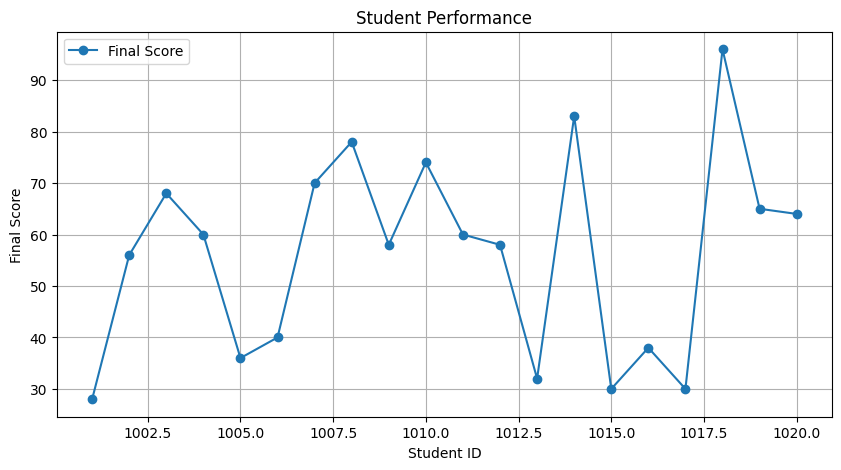

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(df['Student_ID'][:20], df['Final_Score'][:20], marker = 'o', label='Final Score')

plt.title('Student Performance')
plt.xlabel('Student ID')
plt.ylabel('Final Score')

plt.legend()
plt.grid()
plt.show()


##Bar chart showing average scores by department.


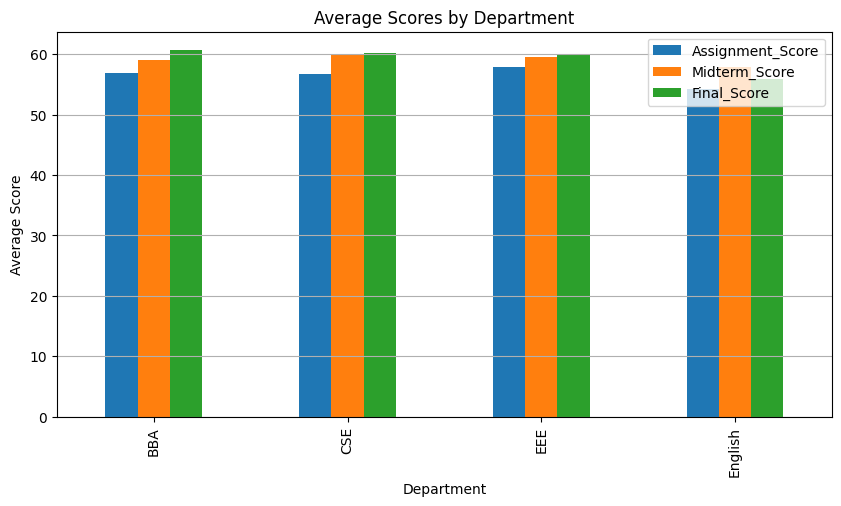

In [48]:
department_avg.plot(  kind='bar',
    figsize=(10, 5))

plt.title('Average Scores by Department')
plt.xlabel('Department')
plt.ylabel('Average Score')

plt.legend()
plt.grid(axis='y')

plt.show()

##Histogram showing student age distribution.

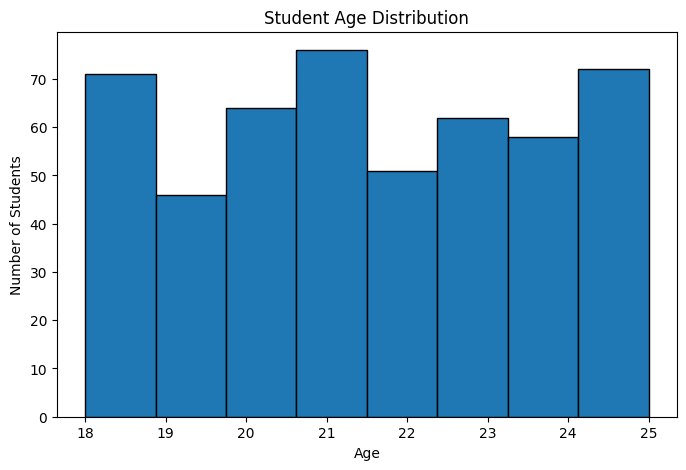

In [50]:
plt.figure(figsize=(8, 5))

plt.hist(df['Age'],bins=8,edgecolor='black')
plt.title('Student Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Students')



plt.show()

##Scatter plot showing study hours vs final score.

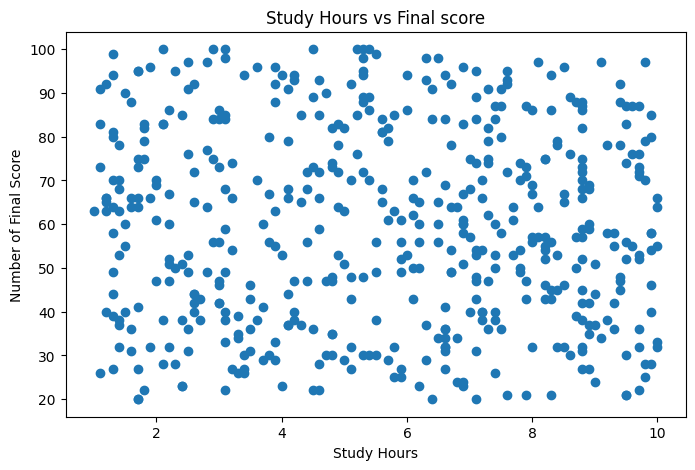

In [57]:

plt.figure(figsize=(8, 5))
plt.scatter( df['Study_Hours'], df['Final_Score'])



plt.title('Study Hours vs Final score')
plt.xlabel('Study Hours')
plt.ylabel('Number of Final Score')
plt.show()


##Pie chart showing department-wise student percentage.

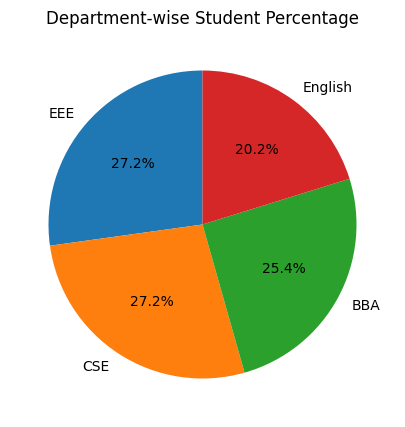

In [62]:
plt.figure(figsize=(8, 5))
dept_count = df['Department'].value_counts()

plt.pie( dept_count ,  labels=dept_count.index,
    autopct='%1.1f%%',
    startangle=90)

plt.title('Department-wise Student Percentage')

plt.show()

##Boxplot showing final score distribution

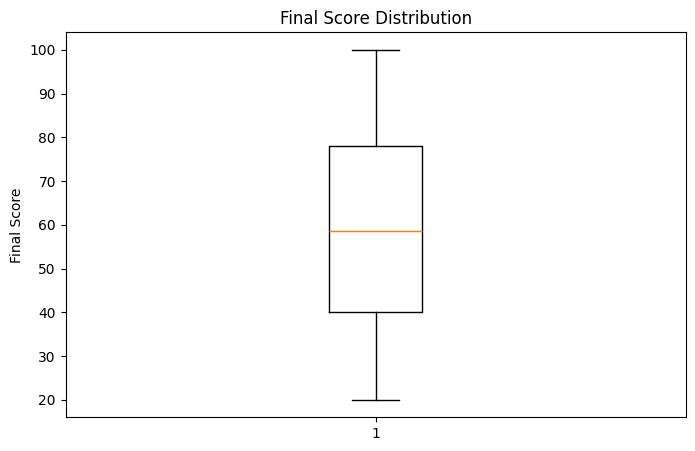

In [61]:
plt.figure(figsize=(8, 5))

plt.boxplot(df['Final_Score'])

plt.title('Final Score Distribution')
plt.ylabel('Final Score')


plt.show()

#Seaborn

##histplot() – Distribution of student scores.

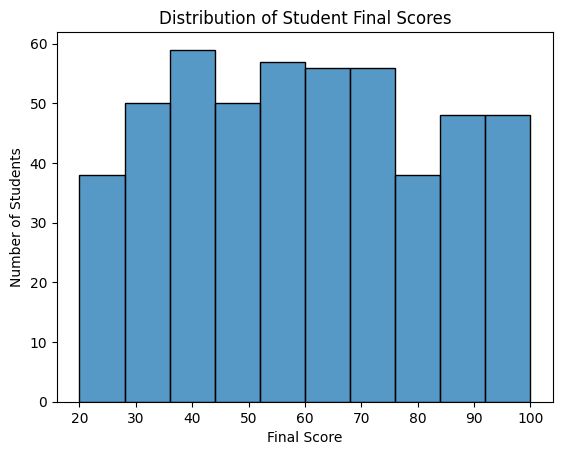

In [64]:
import seaborn as sns

sns.histplot(df['Final_Score'], bins= 10)

plt.title('Distribution of Student Final Scores')
plt.xlabel('Final Score')
plt.ylabel('Number of Students')

plt.show()

##kdeplot() – Density distribution of CGPA.

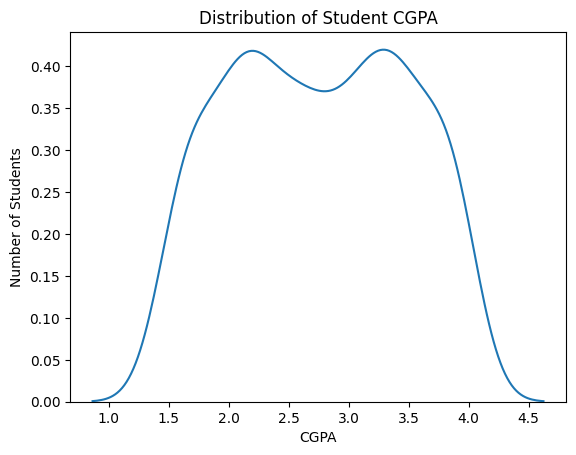

In [65]:
sns.kdeplot(df['CGPA'])

plt.title('Distribution of Student CGPA')
plt.xlabel('CGPA')
plt.ylabel('Number of Students')

plt.show()

##boxplot() – Compare scores across departments.

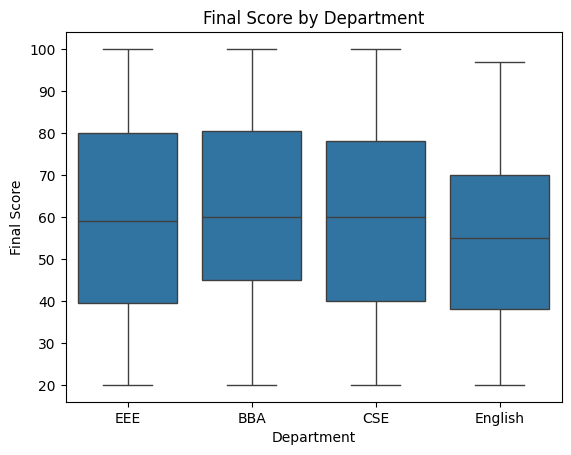

In [66]:
sns.boxplot(data = df , x='Department', y='Final_Score')

plt.title('Final Score by Department')
plt.xlabel('Department')
plt.ylabel('Final Score')

plt.show()

##violinplot() – Distribution of final scores by gender.

Text(0, 0.5, 'Final Score')

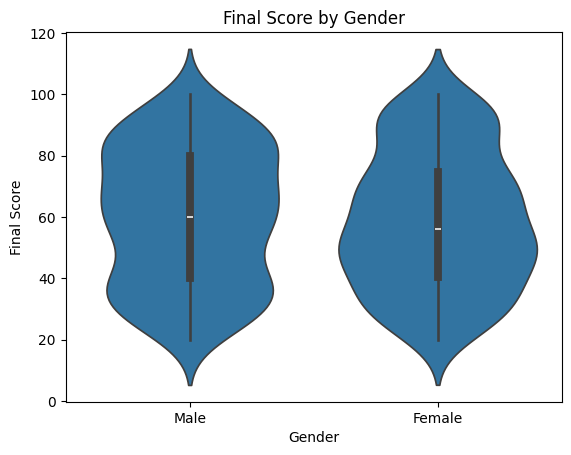

In [67]:
sns.violinplot(data=df, x='Gender', y= 'Final_Score')

plt.title('Final Score by Gender')
plt.xlabel('Gender')
plt.ylabel('Final Score')


##barplot() – Average final score by department.

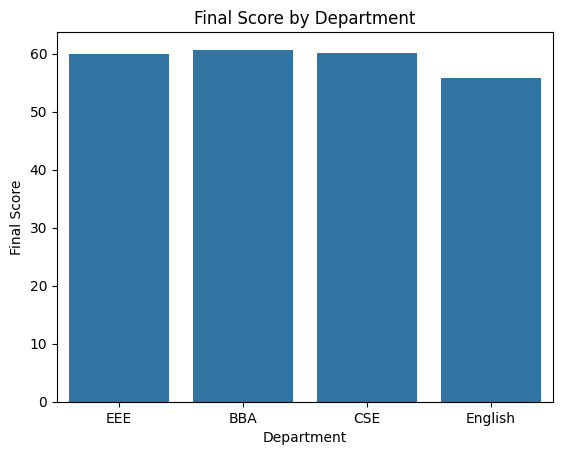

In [69]:
sns.barplot(data= df, x='Department', y='Final_Score', errorbar=None)
plt.title('Final Score by Department')
plt.xlabel('Department')
plt.ylabel('Final Score')

plt.show()


##countplot() – Number of students in each department.

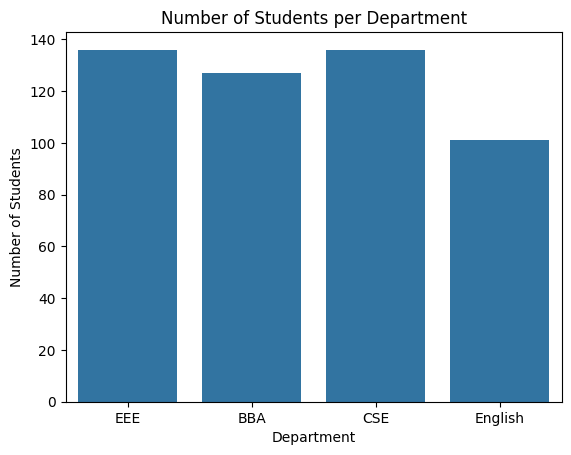

In [70]:
# number_of_student = df['Department'].value_counts()

sns.countplot(data = df, x='Department')

plt.title('Number of Students per Department')
plt.xlabel('Department')
plt.ylabel('Number of Students')

plt.show()

##scatterplot() – Study hours vs final score.

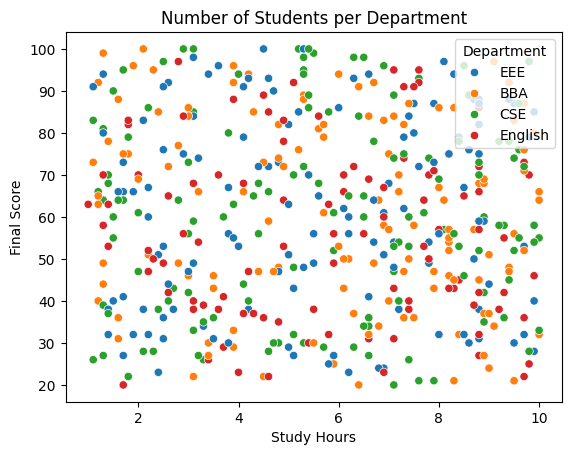

In [73]:
sns.scatterplot(data= df, x='Study_Hours', y='Final_Score', hue='Department')
plt.title('Number of Students per Department')
plt.xlabel('Study Hours')
plt.ylabel('Final Score')

plt.show()

##regplot() – Relationship between attendance and final score.

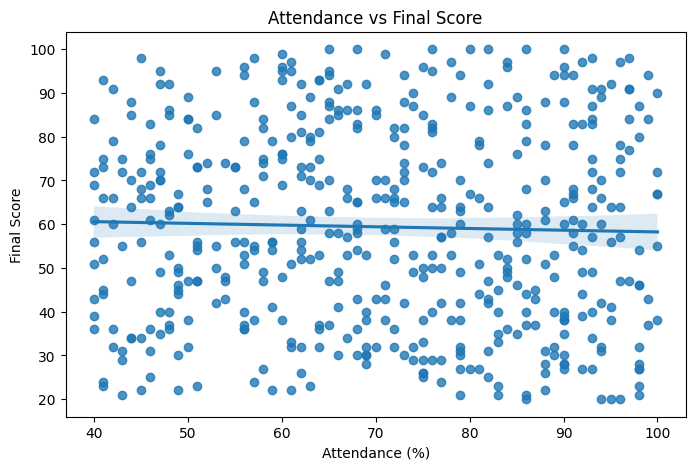

In [74]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x='Attendance',
    y='Final_Score'
)

plt.title('Attendance vs Final Score')
plt.xlabel('Attendance (%)')
plt.ylabel('Final Score')

plt.show()